# Fit Signals: can purchase history reveal a customer's fit preference?

Online shops want to recommend a size and a fit, but a purchase is not a tape measure. This notebook asks a smaller question first: if we look only at trousers and jeans, do customers repeat one fit often enough that the repetition is unlikely to be the shop's mix alone?

There is no machine learning model and no product image. There are four steps:

1. Read a fit from the product text.
2. Describe how those fits are distributed, including over time and by age.
3. Test whether customers are more consistent than a shuffled baseline.
4. Say what that means for a recommender, and where the evidence stops.


### Before the four steps: keep the laptop upright

`transactions_train.csv` is about 3 GB, and this computer has 8 GB of memory, much of it already in use. Loading the whole file would stall or crash the kernel. We only need trousers and jeans, and only a few fields.

The notebook therefore:

- reads the transactions file in chunks of 250,000 rows
- keeps three raw columns: date, customer, and article
- keeps a row only when the article is a trouser or a jean
- replaces the 64-character customer id with a numeric key, then attaches age and a fit code
- saves that smaller table as `data/trousers_transactions.parquet`

Parquet is a compact column format. The next run reads the small file and skips the 3 GB scan. The raw files and the parquet live in `data/`, which is gitignored, because they are large and come from Kaggle.

The customer key is the first 16 hex characters of the customer id, read as a number. The same person always gets the same number. We check that no two people in the customer file share a key. The charts only need "same customer or not", so the original 64-character id is not kept in the analysis table.


In [1]:
from pathlib import Path
import gc
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from scipy.stats import chi2_contingency

ROOT = Path.cwd()
DATA = ROOT / "data"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

if not (DATA / "articles.csv").exists():
    raise FileNotFoundError(
        "Run this notebook from the fit-signals folder, with the Kaggle files in data/."
    )

PARQUET = DATA / "trousers_transactions.parquet"
PARQUET_TMP = DATA / "trousers_transactions.parquet.tmp"
CHUNK_SIZE = 250_000
MIN_PURCHASES = 5
N_PERMUTATIONS = 1000

FIT_ORDER = [
    "slim/skinny",
    "regular/straight",
    "relaxed/loose/wide",
    "oversized",
]
WAIST_ORDER = ["high", "regular", "low"]
COLORS = {
    "slim/skinny": "#24527a",
    "regular/straight": "#3d7a5a",
    "relaxed/loose/wide": "#d4922a",
    "oversized": "#9c3b3b",
}
AGE_BINS = [15, 24, 34, 44, 54, 120]
AGE_LABELS = ["16–24", "25–34", "35–44", "45–54", "55+"]

plt.rcParams.update({
    "figure.figsize": (8.6, 4.6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "font.size": 11,
})


def save_figure(fig, name):
    fig.savefig(FIG / name, dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)


def customer_key(ids: pd.Series) -> np.ndarray:
    # First 16 hex characters of the customer id, as a signed 64-bit integer.
    prefixes = ids.str.slice(0, 16).to_numpy()
    unsigned = np.empty(len(prefixes), dtype=np.uint64)
    for i, prefix in enumerate(prefixes):
        unsigned[i] = int(prefix, 16)
    return unsigned.view(np.int64)


### Which products count as trousers and jeans

The catalogue mixes trousers with shorts, leggings, skirts, and jersey pants. We keep a product only when `product_type_name` is Trousers and `garment_group_name` is Trousers or Trousers Denim. That is woven trousers and denim trousers, which is where the jeans sit. Everything else stays out, so the fit words we count later refer to the same kind of garment.


In [2]:
articles = pd.read_csv(
    DATA / "articles.csv",
    usecols=[
        "article_id",
        "prod_name",
        "product_type_name",
        "garment_group_name",
        "detail_desc",
    ],
    dtype={
        "article_id": "int64",
        "prod_name": "string",
        "product_type_name": "string",
        "garment_group_name": "string",
        "detail_desc": "string",
    },
)

is_trouser = articles["product_type_name"] == "Trousers"
is_bottom = articles["garment_group_name"].isin(["Trousers", "Trousers Denim"])
articles = articles.loc[is_trouser & is_bottom].reset_index(drop=True)

print(f"Trouser and jean products: {len(articles):,}")
print(articles["garment_group_name"].value_counts().to_string())


Trouser and jean products: 7,599
garment_group_name
Trousers          5489
Trousers Denim    2110


### 1. Fit labelling: the catalogue has no fit column

H&M does not give us a field called fit. The cut is written in the product name and the description: "skinny", "relaxed fit", "straight leg", "high waist". We search the lowercased name and description with keyword rules.

The leg-fit label keeps the first match, in this order:

- oversized
- wide leg or wide fit (part of relaxed/loose/wide; checked first so it is not beaten by the word slim)
- slim/skinny, including super-skinny
- relaxed or loose
- regular/straight (`regular` alone does not count, because in this catalogue it almost always means "regular waist")

"Relaxed skinny" is labelled slim/skinny. Skinny is the cut the product is sold as, and skinny is checked before relaxed. A wide leg is the exception: a few texts say "slim from the hips" and "wide legs" in the same sentence, and the leg opening is the wide one, so wide leg wins.

Waist is a second label, not a replacement: high, low, or regular waist. A product can have both, only one, or neither.

Coverage is the share of trouser and jean products that receive a leg-fit label. If coverage is low, or the ten examples look wrong, the charts below are not trustworthy. Colour variants share the same text, so each sample is ten different product names, not ten colours of one jean. The sample is fixed with `random_state=42`.

Before trusting the rules on the catalogue, we check them on sentences written by hand, including the "wide jersey ribbing" trap.


In [3]:
# Earlier rules win. That is the whole priority policy.
# Wide leg is its own rule, above slim. The same class name is allowed twice:
# first match wins, so a later "relaxed" or "loose" only fills rows still empty.
FIT_RULES = [
    ("oversized", r"\b(?:oversized|oversize|over-sized)\b"),
    ("relaxed/loose/wide", r"\bwide[- ](?:leg|fit)s?\b"),
    ("slim/skinny", r"\b(?:super[- ]?)?(?:skinny|slim)(?:[- ]fit)?\b"),
    ("relaxed/loose/wide", r"\b(?:relaxed|loose)(?:[- ]fit)?\b"),
    ("regular/straight", r"\bstraight(?:[- ](?:leg|fit))?\b|\bregular[- ]fit\b"),
]
WAIST_RULES = [
    ("high", r"\bhigh[- ]?waist(?:ed)?\b"),
    ("low", r"\blow[- ]?(?:waist(?:ed)?|rise)\b"),
    ("regular", r"\bregular[- ]waist\b"),
]


def match_label(text: pd.Series, rules: list[tuple[str, str]]) -> pd.Series:
    # First matching rule wins. Unmatched rows stay missing.
    labels = pd.Series(pd.NA, index=text.index, dtype="object")
    free = pd.Series(True, index=text.index)
    for name, pattern in rules:
        hit = free & text.str.contains(pattern, regex=True, na=False)
        labels.loc[hit] = name
        free = free & ~hit
    return labels.astype("string")


text = (
    articles["prod_name"].fillna("") + " " + articles["detail_desc"].fillna("")
).str.lower()
articles["fit_label"] = match_label(text, FIT_RULES)
articles["waist_label"] = match_label(text, WAIST_RULES)
articles["fit_code"] = (
    articles["fit_label"].map({name: i for i, name in enumerate(FIT_ORDER)}).fillna(-1).astype("int8")
)

checks = [
    ("5-pocket skinny jeans with a regular waist", "slim/skinny", "regular"),
    ("wide jersey ribbing at the waist. skinny legs", "slim/skinny", None),
    ("relaxed skinny 5pkt", "slim/skinny", None),
    ("trousers with a relaxed fit", "relaxed/loose/wide", None),
    ("wide-leg jeans", "relaxed/loose/wide", None),
    ("wide legs and a high waist", "relaxed/loose/wide", "high"),
    ("straight-leg trousers", "regular/straight", None),
    ("a regular waist and straight silhouette", "regular/straight", "regular"),
    ("suit trousers with a regular waist", None, "regular"),
    ("low-rise joggers in a loose fit", "relaxed/loose/wide", "low"),
    ("oversized trousers", "oversized", None),
    ("super-skinny jeans", "slim/skinny", None),
    ("slim fit from the hips and wide legs", "relaxed/loose/wide", None),
]
check_text = pd.Series([row[0] for row in checks])
got_fit = match_label(check_text, FIT_RULES)
got_waist = match_label(check_text, WAIST_RULES)


def same_label(got, expected) -> bool:
    if expected is None:
        return bool(pd.isna(got))
    return got == expected


for i, (sentence, expected_fit, expected_waist) in enumerate(checks):
    if not same_label(got_fit.iloc[i], expected_fit) or not same_label(got_waist.iloc[i], expected_waist):
        raise AssertionError(
            f"{sentence!r} -> fit {got_fit.iloc[i]!r}, waist {got_waist.iloc[i]!r}"
        )
print(f"Hand-written checks passed ({len(checks)} sentences), including the wide-jersey trap.")

n_products = len(articles)
n_fit = int(articles["fit_label"].notna().sum())
n_waist = int(articles["waist_label"].notna().sum())
print(
    f"Leg-fit coverage: {n_fit / n_products:.1%} "
    f"({n_fit:,} of {n_products:,} trouser and jean products)."
)
print(
    f"Waist coverage: {n_waist / n_products:.1%} "
    f"({n_waist:,} of {n_products:,} products)."
)
print("\nLeg-fit counts, including products with no match:")
print(articles["fit_label"].value_counts(dropna=False).to_string())
print("\nWaist counts, including products with no match:")
print(articles["waist_label"].value_counts(dropna=False).to_string())


def print_examples(column: str, classes: list[str], n: int = 10) -> None:
    for label in classes:
        pool = articles.loc[articles[column] == label].drop_duplicates("prod_name")
        print(f"\n{label} — {len(pool):,} distinct product names")
        if pool.empty:
            print("  No product matched this class.")
            continue
        sample = pool.sample(n=min(n, len(pool)), random_state=42)
        for rank, row in enumerate(sample.itertuples(index=False), start=1):
            desc = "" if pd.isna(row.detail_desc) else " ".join(str(row.detail_desc).split())
            if len(desc) > 140:
                desc = desc[:137] + "..."
            fit = "none" if pd.isna(row.fit_label) else row.fit_label
            waist = "none" if pd.isna(row.waist_label) else row.waist_label
            print(f"  {rank}. [{int(row.article_id):010d}] {row.prod_name}")
            print(f"     group: {row.garment_group_name} | leg fit: {fit} | waist: {waist}")
            print(f"     {desc}")


print("\n========== Ten examples per leg-fit class ==========")
print_examples("fit_label", FIT_ORDER)
print("\n========== Ten examples per waist class ==========")
print_examples("waist_label", WAIST_ORDER)


Hand-written checks passed (13 sentences), including the wide-jersey trap.
Leg-fit coverage: 65.7% (4,994 of 7,599 trouser and jean products).
Waist coverage: 42.9% (3,258 of 7,599 products).

Leg-fit counts, including products with no match:
fit_label
slim/skinny           3426
<NA>                  2605
relaxed/loose/wide     890
regular/straight       678

Waist counts, including products with no match:
waist_label
<NA>       4341
high       1635
regular    1444
low         179

========== Ten examples per leg-fit class ==========

slim/skinny — 1,192 distinct product names
  1. [0783147002] Skinny Stripes
     group: Trousers Denim | leg fit: slim/skinny | waist: regular
     5-pocket jeans in washed, stretch denim with a regular waist, zip fly and button, and skinny legs with a coloured stripe down the sides. ...
  2. [0563364001] Phoenix Denim
     group: Trousers | leg fit: slim/skinny | waist: regular
     5-pocket jeans in stretch denim with a regular waist, button fly and ski

### Attaching the labels to purchases

The labels above live on products. The question lives on purchases. We stream the transactions file, keep purchases of the products selected above, and store a small row: the date, the numeric customer key, the fit code (`-1` means the product had no leg-fit word), and the customer's age.

Age comes from `customers.csv`, also read in chunks, and reduced to the same numeric key before the big scan starts. After the parquet file exists, this cell only reads that file.


In [4]:
key_parts = []
age_parts = []
n_customers = 0
for chunk in pd.read_csv(
    DATA / "customers.csv",
    usecols=["customer_id", "age"],
    dtype={"customer_id": "string", "age": "float32"},
    chunksize=CHUNK_SIZE,
):
    key_parts.append(customer_key(chunk["customer_id"]))
    age_parts.append(chunk["age"].to_numpy(dtype="float32"))
    n_customers += len(chunk)

customer_keys = np.concatenate(key_parts)
customer_ages = np.concatenate(age_parts)
del key_parts, age_parts
age_by_key = pd.Series(customer_ages, index=pd.Index(customer_keys, dtype="int64"))
del customer_keys, customer_ages
if age_by_key.index.has_duplicates:
    raise RuntimeError("Two customers produced the same numeric key. Refusing to continue.")
print(f"Customer file: {n_customers:,} people, {len(age_by_key):,} distinct keys. No collisions.")

fit_by_article = pd.Series(
    articles["fit_code"].to_numpy(),
    index=articles["article_id"].to_numpy(),
)
trouser_ids = set(articles["article_id"].tolist())


def compact_rows(keep: pd.DataFrame) -> pd.DataFrame:
    keys = customer_key(keep["customer_id"])
    # map, not reindex: a chunk contains the same article more than once.
    fit_codes = keep["article_id"].map(fit_by_article).fillna(-1).to_numpy(dtype="int8")
    ages = pd.Series(keys).map(age_by_key).to_numpy(dtype="float32")
    return pd.DataFrame({
        "t_dat": pd.to_datetime(keep["t_dat"]),
        "customer_key": keys,
        "fit_code": fit_codes,
        "age": ages,
    })


if PARQUET.exists():
    print(f"Filtered file already exists: {PARQUET.name}. Skipping the 3 GB scan.")
else:
    if PARQUET_TMP.exists():
        PARQUET_TMP.unlink()
    writer = None
    kept_rows = 0
    scanned_rows = 0
    next_report = 1_000_000
    try:
        reader = pd.read_csv(
            DATA / "transactions_train.csv",
            usecols=["t_dat", "customer_id", "article_id"],
            dtype={"t_dat": "string", "customer_id": "string", "article_id": "int64"},
            chunksize=CHUNK_SIZE,
        )
        for chunk in reader:
            scanned_rows += len(chunk)
            keep = chunk.loc[
                chunk["article_id"].isin(trouser_ids),
                ["t_dat", "customer_id", "article_id"],
            ].copy()
            del chunk
            if not keep.empty:
                compact = compact_rows(keep)
                del keep
                table = pa.Table.from_pandas(compact, preserve_index=False)
                kept_rows += len(compact)
                del compact
                if writer is None:
                    writer = pq.ParquetWriter(PARQUET_TMP, table.schema, compression="snappy")
                writer.write_table(table)
                del table
            if scanned_rows >= next_report:
                print(f"Scanned {scanned_rows:,} rows, kept {kept_rows:,}", flush=True)
                next_report += 1_000_000
                gc.collect()
        if writer is None:
            raise RuntimeError("No trouser or jean purchases were found.")
        writer.close()
        writer = None
        os.replace(PARQUET_TMP, PARQUET)
        print(f"Saved {kept_rows:,} trouser and jean purchases to {PARQUET.name}.")
    finally:
        if writer is not None:
            writer.close()
            if PARQUET_TMP.exists():
                PARQUET_TMP.unlink()

del age_by_key, fit_by_article, trouser_ids
gc.collect()

tx = pd.read_parquet(PARQUET)
csv_gb = (DATA / "transactions_train.csv").stat().st_size / 1e9
parquet_mb = PARQUET.stat().st_size / 1e6
n_tx = len(tx)
n_labelled_tx = int((tx["fit_code"] >= 0).sum())
print(f"Transactions file {csv_gb:.2f} GB -> filtered parquet {parquet_mb:.1f} MB ({n_tx:,} rows).")
print(
    f"Purchases with a leg-fit label: {n_labelled_tx:,} "
    f"({n_labelled_tx / n_tx:.1%} of trouser and jean purchases)."
)
print(f"Purchases with no age: {int(tx['age'].isna().sum()):,} of {n_tx:,}.")
print(
    f"Dates run from {tx['t_dat'].min():%d %b %Y} to {tx['t_dat'].max():%d %b %Y}."
)

labelled = tx.loc[tx["fit_code"] >= 0, ["t_dat", "customer_key", "fit_code", "age"]].copy()
del tx
gc.collect()
print(f"Distinct customers in labelled purchases: {labelled['customer_key'].nunique():,}")


Customer file: 1,371,980 people, 1,371,980 distinct keys. No collisions.


Scanned 1,000,000 rows, kept 142,595


Scanned 2,000,000 rows, kept 282,601


Scanned 3,000,000 rows, kept 412,014


Scanned 4,000,000 rows, kept 532,908


...

Scanned 29,000,000 rows, kept 3,371,975


Scanned 30,000,000 rows, kept 3,462,171


Scanned 31,000,000 rows, kept 3,570,087


Saved 3,681,181 trouser and jean purchases to trousers_transactions.parquet.


Transactions file 3.49 GB -> filtered parquet 26.2 MB (3,681,181 rows).
Purchases with a leg-fit label: 2,626,966 (71.4% of trouser and jean purchases).
Purchases with no age: 15,895 of 3,681,181.
Dates run from 20 Sep 2018 to 22 Sep 2020.
Distinct customers in labelled purchases: 584,957


### 2. Description: the background picture

The main test asks whether a customer repeats a fit. That number is easy to misread if we skip the background.

First, the mix. If most labelled purchases are skinny, then even a customer choosing at random will often "prefer" skinny. We plot the share of each fit among labelled purchases, and we print the same shares among products, so a popular fit is not confused with a large shelf of products.

Second, time. Fashion shifts. If skinny's share falls month by month, part of what looks like a personal habit may be the month the customer shopped. The line chart is the share of labelled purchases in each month.

Third, age. We group customers into 16–24, 25–34, 35–44, 45–54, and 55 or older, and plot each group's fit mix. Age 24 is in the first group and age 25 is in the next. Missing ages, and any age outside 16 to 120, stay out of this chart.

A chi-square test asks whether age group and fit would line up this way if they were independent. With millions of rows, a tiny difference can produce a tiny p-value, so we also report Cramer's V, which measures the size of the link rather than only whether it exists. A common rule of thumb calls V near 0.1 small and V near 0.3 moderate. One more caution: the rows are purchases, and one customer can appear many times, so the purchases are not independent and the p-value is too confident. The share table is the thing to trust.


Share of each fit among labelled products and among labelled purchases:


,products %,purchases %
slim/skinny,68.6,78.1
regular/straight,13.6,10.0
relaxed/loose/wide,17.8,11.9


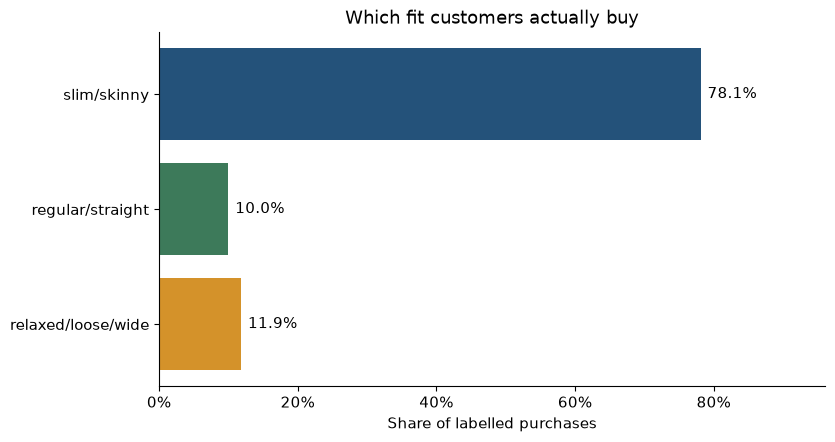

In the rules, but absent from labelled purchases: oversized.


In [5]:
purchase_counts = labelled["fit_code"].value_counts().sort_index()
purchase_share = purchase_counts / purchase_counts.sum()
purchase_share.index = [FIT_ORDER[int(i)] for i in purchase_share.index]

product_counts = articles.loc[articles["fit_code"] >= 0, "fit_code"].value_counts().sort_index()
product_share = product_counts / product_counts.sum()
product_share.index = [FIT_ORDER[int(i)] for i in product_share.index]

compare = pd.DataFrame({
    "products %": (product_share * 100).round(1),
    "purchases %": (purchase_share * 100).round(1),
})
compare = compare.reindex([name for name in FIT_ORDER if name in compare.index])
print("Share of each fit among labelled products and among labelled purchases:")
display(compare)

present = [name for name in FIT_ORDER if name in purchase_share.index]
fig, ax = plt.subplots()
y = np.arange(len(present))
values = purchase_share.reindex(present).to_numpy()
ax.barh(y, values, color=[COLORS[name] for name in present])
ax.set_yticks(y, present)
ax.invert_yaxis()
ax.set_xlim(0, min(1, float(values.max()) + 0.18))
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
for yi, value in enumerate(values):
    ax.text(value + 0.01, yi, f"{value:.1%}", va="center")
ax.set_xlabel("Share of labelled purchases")
ax.set_title("Which fit customers actually buy")
save_figure(fig, "fit_distribution.png")

missing = [name for name in FIT_ORDER if name not in present]
if missing:
    print("In the rules, but absent from labelled purchases: " + ", ".join(missing) + ".")


Months in the chart: 25 (the calendar span is 25 months).
Lowest month to highest month for each fit:
  slim/skinny: 58.6% (2019-06) to 87.6% (2019-12)
  regular/straight: 5.1% (2019-01) to 25.4% (2020-06)
  relaxed/loose/wide: 6.1% (2019-11) to 30.0% (2019-06)
Largest swing across months: 29.0%.


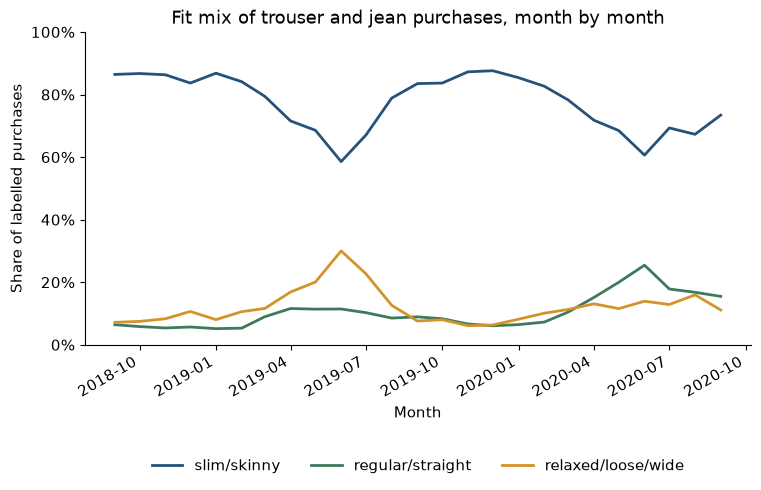

In [6]:
month = labelled["t_dat"].dt.to_period("M")
month_counts = pd.crosstab(month, labelled["fit_code"]).sort_index()
month_counts = month_counts.loc[:, month_counts.sum() > 0]
month_counts.columns = [FIT_ORDER[int(col)] for col in month_counts.columns]
month_share = month_counts.div(month_counts.sum(axis=1), axis=0)
max_month_swing = float((month_share.max() - month_share.min()).max())

x = pd.to_datetime(month_share.index.astype(str))
span = (x.max().to_period("M") - x.min().to_period("M")).n + 1
print(f"Months in the chart: {len(x)} (the calendar span is {span} months).")
print("Lowest month to highest month for each fit:")
for name in month_share.columns:
    low_at = month_share[name].idxmin()
    high_at = month_share[name].idxmax()
    print(
        f"  {name}: {month_share[name].min():.1%} ({low_at}) to "
        f"{month_share[name].max():.1%} ({high_at})"
    )
print(f"Largest swing across months: {max_month_swing:.1%}.")

fig, ax = plt.subplots()
for name in month_share.columns:
    ax.plot(x, month_share[name].to_numpy(), label=name, color=COLORS[name], linewidth=2)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Month")
ax.set_ylabel("Share of labelled purchases")
ax.set_title("Fit mix of trouser and jean purchases, month by month")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.32))
fig.autofmt_xdate()
save_figure(fig, "fit_shares_by_month.png")


Labelled purchases with no age: 11,355.
Labelled purchases with an age outside 16–120: 0.


Fit share within each age group (%):


,slim/skinny,regular/straight,relaxed/loose/wide
age,,,
16–24,78.3,10.4,11.2
25–34,77.2,10.4,12.4
35–44,80.2,8.5,11.3
45–54,80.5,8.8,10.7
55+,73.8,12.2,14.0


Chi-square = 7152.5, degrees of freedom = 8, p = 0, Cramer's V = 0.037.
Smallest expected cell count: 31320.
By the usual rule of thumb, V = 0.037 is a small association.
Purchases from the same customer are not independent, so this p-value is too sure of itself. Use the share table and Cramer's V, not the p-value alone.


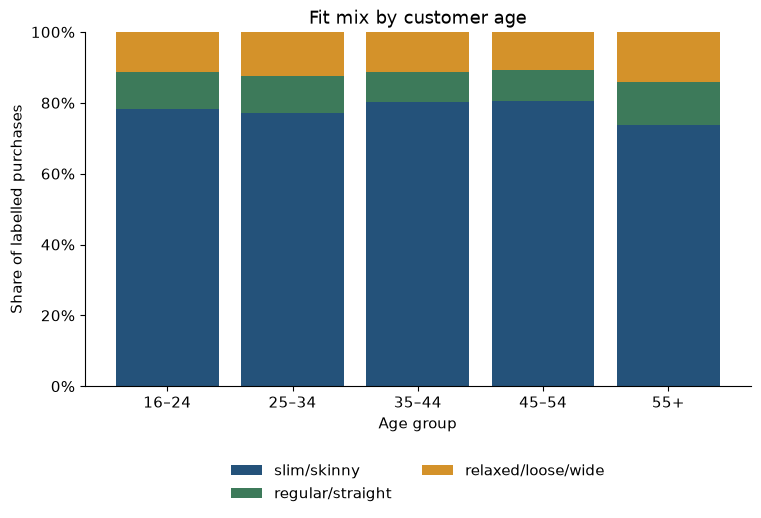

In [7]:
age_group = pd.cut(labelled["age"], bins=AGE_BINS, labels=AGE_LABELS)
n_missing_age = int(labelled["age"].isna().sum())
n_outside_age = int(age_group.isna().sum()) - n_missing_age
print(f"Labelled purchases with no age: {n_missing_age:,}.")
print(f"Labelled purchases with an age outside 16–120: {n_outside_age:,}.")

known = age_group.notna()
age_counts = pd.crosstab(age_group[known], labelled.loc[known, "fit_code"])
age_counts = age_counts.loc[:, age_counts.sum() > 0]
age_counts.columns = [FIT_ORDER[int(col)] for col in age_counts.columns]
age_share = age_counts.div(age_counts.sum(axis=1), axis=0)

print("Fit share within each age group (%):")
display((age_share * 100).round(1))

chi2, chi_p, dof, expected = chi2_contingency(age_counts)
n_obs = int(age_counts.to_numpy().sum())
r, k = age_counts.shape
cramer_v = float(np.sqrt(chi2 / (n_obs * min(r - 1, k - 1))))
print(
    f"Chi-square = {chi2:.1f}, degrees of freedom = {dof}, "
    f"p = {chi_p:.3g}, Cramer's V = {cramer_v:.3f}."
)
print(f"Smallest expected cell count: {expected.min():.0f}.")
if cramer_v < 0.1:
    size_word = "small"
elif cramer_v < 0.3:
    size_word = "moderate"
else:
    size_word = "large"
print(f"By the usual rule of thumb, V = {cramer_v:.3f} is a {size_word} association.")
print(
    "Purchases from the same customer are not independent, so this p-value is too sure of itself. "
    "Use the share table and Cramer's V, not the p-value alone."
)

fig, ax = plt.subplots()
age_share.plot(
    kind="bar",
    stacked=True,
    color=[COLORS[name] for name in age_share.columns],
    ax=ax,
    width=0.82,
)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Age group")
ax.set_ylabel("Share of labelled purchases")
ax.set_title("Fit mix by customer age")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
save_figure(fig, "fit_shares_by_age.png")


### 3. Consistency: the main question

We keep customers with at least five labelled trouser or jean purchases. With one purchase, consistency is always 100%, which would fake a strong result.

For each customer, consistency is the share of their purchases that fall in their most common fit. Five skinny purchases score 1. Three skinny and two relaxed score 0.6. If two fits are tied, we use that tied count. We then average these scores. Each customer counts once: someone with 40 purchases does not outvote someone with 5.

A high average is not yet evidence of a personal preference. We compare it with a permutation baseline. We shuffle the fit labels across these purchases 1,000 times. Each customer keeps the same number of purchases, and the pile of fit labels keeps the same overall mix, but the link between a person and a fit is broken. If shoppers have no personal fit, the real average should sit inside that cloud of shuffles.

The p-value is the share of shuffles whose average is at least as high as the real one. We add one to the numerator and the denominator, so beating every shuffle is reported as about 1 in 1,001 rather than as zero. The histogram shows the shuffles. With this many customers the average barely moves, so the cloud is a thin spike. The left panel zooms in on that spike. The right panel puts the real average beside it on a wider scale, and that axis does not start at zero, otherwise a gap of a few points would be invisible.

The shuffle does not keep the month fixed. If the monthly chart moves a lot, some of the consistency can come from shopping in a period when one fit dominated. Read the monthly chart before quoting the p-value.


Finished 200 of 1,000 shuffles


Finished 400 of 1,000 shuffles


Finished 600 of 1,000 shuffles


Finished 800 of 1,000 shuffles


Finished 1,000 of 1,000 shuffles


Customers with at least 5 labelled purchases: 169,759.
Purchases in that group: 1,814,501.
Purchases per customer — median 8, mean 10.7.
Observed average consistency: 83.66%.
Shuffle average: 79.89% (middle 95% of shuffles: 79.860% to 79.927%).
Shuffles at least as high as the observed value: 0 of 1000.
One-sided p-value = (1 + 0) / (1 + 1000) = 0.0010.


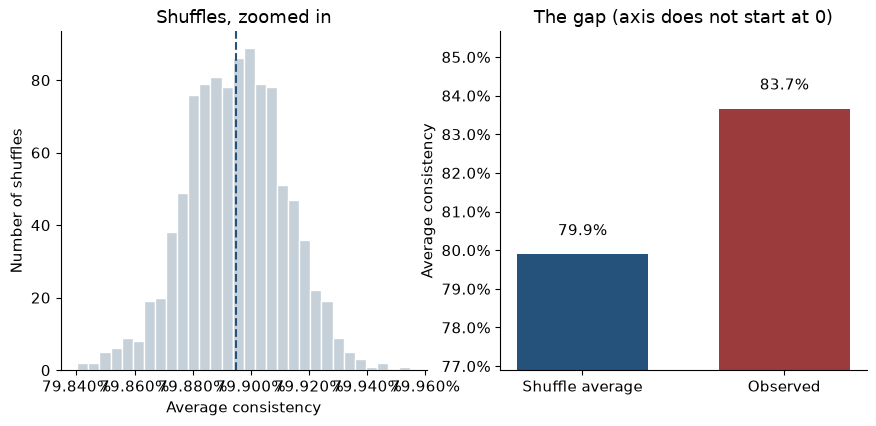

In [8]:
per_customer = labelled.groupby("customer_key", sort=False).size()
eligible = per_customer[per_customer >= MIN_PURCHASES].index
cohort = labelled.loc[
    labelled["customer_key"].isin(eligible),
    ["customer_key", "fit_code"],
]
dense, _ = pd.factorize(cohort["customer_key"].to_numpy(), sort=False)
sizes = np.bincount(dense)
fit_codes = cohort["fit_code"].to_numpy(dtype=np.int8)
n_customers_cohort = int(sizes.shape[0])
n_fits = len(FIT_ORDER)
if fit_codes.min() < 0 or fit_codes.max() >= n_fits:
    raise RuntimeError("Fit codes are outside 0 .. number of fit classes.")

base = dense.astype(np.int64) * n_fits


def average_consistency(codes: np.ndarray) -> float:
    counts = np.bincount(base + codes, minlength=n_customers_cohort * n_fits)
    mode_share = counts.reshape(n_customers_cohort, n_fits).max(axis=1) / sizes
    return float(mode_share.mean())


observed = average_consistency(fit_codes)
perm_rng = np.random.default_rng(42)
null_stats = np.empty(N_PERMUTATIONS, dtype=np.float64)
for i in range(N_PERMUTATIONS):
    null_stats[i] = average_consistency(perm_rng.permutation(fit_codes))
    if (i + 1) % 200 == 0:
        print(f"Finished {i + 1:,} of {N_PERMUTATIONS:,} shuffles", flush=True)

null_mean = float(null_stats.mean())
null_lo = float(np.quantile(null_stats, 0.025))
null_hi = float(np.quantile(null_stats, 0.975))
n_as_high = int(np.sum(null_stats >= observed))
p_value = (n_as_high + 1) / (N_PERMUTATIONS + 1)

print(f"Customers with at least {MIN_PURCHASES} labelled purchases: {n_customers_cohort:,}.")
print(f"Purchases in that group: {len(cohort):,}.")
print(f"Purchases per customer — median {np.median(sizes):.0f}, mean {sizes.mean():.1f}.")
print(f"Observed average consistency: {observed:.2%}.")
print(
    f"Shuffle average: {null_mean:.2%} "
    f"(middle 95% of shuffles: {null_lo:.3%} to {null_hi:.3%})."
)
print(f"Shuffles at least as high as the observed value: {n_as_high} of {N_PERMUTATIONS}.")
print(f"One-sided p-value = (1 + {n_as_high}) / (1 + {N_PERMUTATIONS}) = {p_value:.4f}.")

fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.4))
axes[0].hist(null_stats, bins=30, color="#c5d0d8", edgecolor="white")
axes[0].axvline(null_mean, color="#24527a", linewidth=1.5, linestyle="--")
axes[0].xaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set_xlabel("Average consistency")
axes[0].set_ylabel("Number of shuffles")
axes[0].set_title("Shuffles, zoomed in")

floor = min(null_mean, observed) - 0.03
ceiling = max(null_mean, observed) + 0.02
axes[1].bar(
    ["Shuffle average", "Observed"],
    [null_mean, observed],
    color=["#24527a", "#9c3b3b"],
    width=0.65,
)
axes[1].set_ylim(floor, ceiling)
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set_ylabel("Average consistency")
axes[1].set_title("The gap (axis does not start at 0)")
for xpos, value in enumerate([null_mean, observed]):
    axes[1].text(xpos, value + 0.004, f"{value:.1%}", ha="center", va="bottom")
save_figure(fig, "consistency_baseline.png")

del cohort
_ = gc.collect()


### 4. Conclusion: what a recommender can take from this

The cell below writes six sentences from the numbers we just computed. They answer the practical question: can these purchases steer a personalised fit recommendation?

Read them with three limits in mind, which the sentences also name. The fit labels are keyword guesses, not a merchandiser's official fit field. A purchase is not a body measurement, so it can steer a cut (skinny versus relaxed) and still say nothing about the centimetres. Returns are not in this file: a pair that shows up several times may be a pair the customer did not keep. If the monthly shares move, some repetition can also be the season they shopped in, because the shuffle does not hold the month fixed.


In [9]:
gap = observed - null_mean
if n_as_high == 0:
    p_text = f"p < {1 / N_PERMUTATIONS:.3f}"
else:
    p_text = f"p = {p_value:.3f}"

sentence_1 = (
    f"Customers with at least {MIN_PURCHASES} labelled trouser or jean purchases "
    f"put {observed:.1%} of those purchases into their single most common fit, on average."
)
sentence_2 = (
    f"When those fit labels are shuffled {N_PERMUTATIONS:,} times, keeping each customer's "
    f"number of purchases and the overall mix, the average is about {null_mean:.1%} "
    f"(the middle 95% of shuffles lie between {null_lo:.2%} and {null_hi:.2%})."
)
if gap >= 0.03 and p_value <= 0.05:
    sentence_3 = (
        f"The real average is {gap * 100:.1f} percentage points higher than that baseline ({p_text}), "
        "so customers repeat a fit more often than the shop's mix would produce by chance."
    )
    sentence_4 = (
        "For a personalised fit recommendation, a short purchase history can act as a prior: "
        "after a few trousers or jeans, later suggestions can lean toward the cut they already repeat."
    )
elif gap > 0 and p_value <= 0.05:
    sentence_3 = (
        f"The real average is only {gap * 100:.1f} percentage points higher than the shuffles ({p_text}): "
        "hard to explain by chance, but too small to lean on by itself."
    )
    sentence_4 = (
        "A recommender could remember the most common fit as a weak prior, "
        "without expecting a large gain from that signal alone."
    )
elif gap <= 0:
    sentence_3 = (
        f"The real average is {abs(gap) * 100:.1f} percentage points below the shuffled baseline ({p_text}), "
        "so these shoppers are not more consistent than the catalogue mix."
    )
    sentence_4 = (
        "A recommender should not treat a few trouser purchases as proof of a stable personal fit."
    )
else:
    sentence_3 = (
        f"The real average is {gap * 100:.1f} percentage points above the shuffles, "
        f"but a gap of that size still shows up often by chance ({p_text})."
    )
    sentence_4 = (
        "This test does not show a clear personal fit signal, "
        "so a recommender should not treat the most common past fit as a reliable preference."
    )
sentence_5 = (
    "What that prior can choose is a cut, such as skinny versus relaxed: "
    "it is not a measured body size and it does not replace a size chart."
)
if max_month_swing >= 0.08:
    sentence_6 = (
        f"The labels are keyword guesses, returns are not recorded, and one fit's share moves by up to "
        f"{max_month_swing * 100:.0f} percentage points across months, so a repeated purchase can be a pair they sent back "
        "or simply the fit the shop was selling when they visited."
    )
else:
    sentence_6 = (
        "The labels are keyword guesses, some products have no fit word, and returns are not recorded, "
        "so a repeated purchase can still be a pair the customer did not keep."
    )

conclusion = " ".join([
    sentence_1,
    sentence_2,
    sentence_3,
    sentence_4,
    sentence_5,
    sentence_6,
])
print(conclusion)


Customers with at least 5 labelled trouser or jean purchases put 83.7% of those purchases into their single most common fit, on average. When those fit labels are shuffled 1,000 times, keeping each customer's number of purchases and the overall mix, the average is about 79.9% (the middle 95% of shuffles lie between 79.86% and 79.93%). The real average is 3.8 percentage points higher than that baseline (p < 0.001), so customers repeat a fit more often than the shop's mix would produce by chance. For a personalised fit recommendation, a short purchase history can act as a prior: after a few trousers or jeans, later suggestions can lean toward the cut they already repeat. What that prior can choose is a cut, such as skinny versus relaxed: it is not a measured body size and it does not replace a size chart. The labels are keyword guesses, returns are not recorded, and one fit's share moves by up to 29 percentage points across months, so a repeated purchase can be a pair they sent back or s